In [21]:
import numpy as np
from matplotlib import pyplot as plt

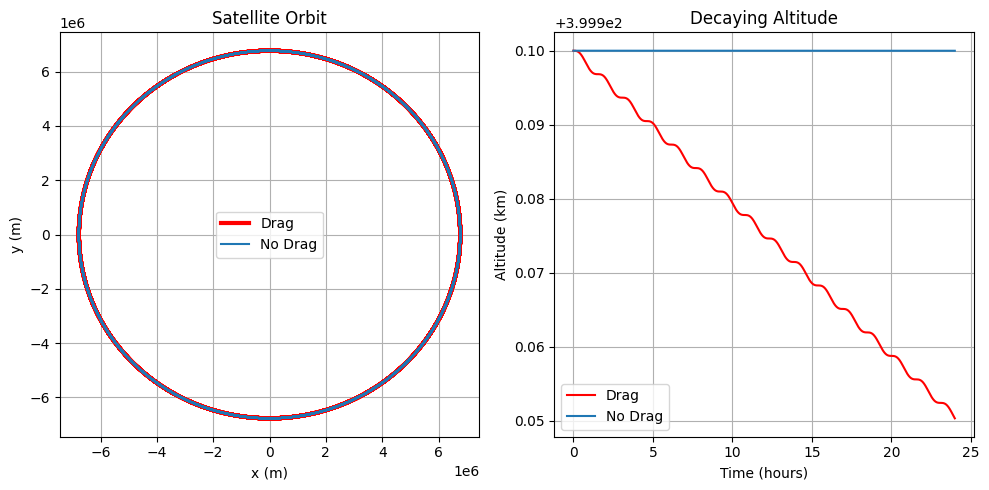

In [26]:
def accel_grav(r):
    r_norm = np.linalg.norm(r)
    return (-mu / r_norm**3) * r

def atm_dens(h):
    return rho_0 * np.exp(-(h - h_ref)/H)
    
def accel_drag(r, v):
    r_mag = np.linalg.norm(r)
    v_mag = np.linalg.norm(v)
    h = r_mag - r_earth
    rho = atm_dens(h)
    if v_mag == 0:
        return np.zeros_like(v)
    else:
        return (-1/2 * (Cd * A / m) * rho * v_mag**2) * (v / v_mag)

def ode_nodrag(t, state):
    r_state = state[:2]
    v_state = state[2:]

    a_state = accel_grav(r_state)

    return np.array([
        v_state[0],
        v_state[1],
        a_state[0],
        a_state[1]
    ])

def ode_drag(t, state):
    r_state = state[:2]
    v_state = state[2:]

    a_drag = accel_drag(r_state, v_state)
    a_gravity = accel_grav(r_state)
    a_total = a_drag + a_gravity
    
    return np.array([
        v_state[0],
        v_state[1],
        a_total[0],
        a_total[1]
    ])

def rk4(f, t, y, h):
    k1 = f(t, y)
    k2 = f(t + 1/2 * h, y + 1/2 * h * k1)
    k3 = f(t + 1/2 * h, y + 1/2 * h * k2)
    k4 = f(t + h, y + h * k3)

    y_next = y + 1/6 * h * (k1 + 2*k2 + 2*k3 + k4)
    return y_next

# Earth constants
mu = 3.9860044e14
r_earth = 6.371e6

# Satellite
Cd = 2.2
m = 1000
A = 10

# Atmosphere model & constants
rho_0 = 5e-13
h_ref = 4.00e5
H = 5e4

r0 = r_earth + h_ref
v0 = np.sqrt(mu / r0)
state_0 = np.array([
    r0,
    0,
    0,
    v0
])

state_drag = state_0.copy()
state_nodrag = state_0.copy()

# Times
t = 0
dt = 10
duration = 86400  # seconds
n_steps = duration // dt
times = []

states_drag = []
states_nodrag = []

for i in range(n_steps):
    times.append(t)
    
    states_drag.append(state_drag.copy())
    state_drag = rk4(ode_drag, t, state_drag, dt)
    
    states_nodrag.append(state_nodrag.copy())
    state_nodrag = rk4(ode_nodrag, t, state_nodrag, dt)
    
    t += dt

times = np.array(times)
states_drag = np.array(states_drag)
states_nodrag = np.array(states_nodrag)

x_drag = states_drag[:, 0]
y_drag = states_drag[:, 1]
vx_drag = states_drag[:, 2]
vy_drag = states_drag[:, 3]

x_nodrag = states_nodrag[:, 0]
y_nodrag = states_nodrag[:, 1]
vx_nodrag = states_nodrag[:, 2]
vy_nodrag = states_nodrag[:, 3]

r_mag_drag = np.sqrt(x_drag**2 + y_drag**2)
altitudes_drag = r_mag_drag - r_earth

r_mag_nodrag = np.sqrt(x_nodrag**2 + y_nodrag**2)
altitudes_nodrag = r_mag_nodrag - r_earth

time_hour = times / 3600

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].plot(x_drag, y_drag, 'r', linewidth=3, label='Drag')
ax[0].plot(x_nodrag, y_nodrag, label='No Drag')
ax[0].set_title('Satellite Orbit')
ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)')
ax[0].grid()
ax[0].legend()

ax[1].plot(time_hour, altitudes_drag / 1000, 'r', label='Drag')
ax[1].plot(time_hour, altitudes_nodrag / 1000, label='No Drag' )
ax[1].set_title('Decaying Altitude')
ax[1].set_xlabel('Time (hours)')
ax[1].set_ylabel('Altitude (km)')
ax[1].grid()
ax[1].legend()

plt.tight_layout()
plt.show()